<a href="https://colab.research.google.com/github/iwemrn/data_analysis_itmo/blob/main/%D0%9B%D0%A01_%D0%95%D1%80%D0%BE%D1%85%D0%B8%D0%BD%D0%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторная работа №1. Иерархический кластерный анализ.**
ФИО: Ерохина Софья Алексеевна
Файл: Леденцы

План выполнения работы:

1.   Загрузка и изучение данных
2.   Подготовка данных
3.   Кластеризация
4.   Построение дендрограммы
5.   Выбор оптимального числа кластеров
6.   Стравнение методов
7.   Вывод





В файле "леденцы.pdf" дано описание данных по признакам. Продублирую их в текущем файле:
* V1: Я потребляю леденцы, чтобы освежить дыхание
* V2: Я потребляю леденцы, чтобы чувствовать себя увереннее
* V3: Я потребляю леденцы, чтобы освежить полость рта
* V4: Я потребляю леденцы, чтобы избавиться от неприятного вкуса во рту
* V5: Я потребляю леденцы как заменитель других кондитерских изделий
* V6: Я потребляю леденцы, когда мне хочется чего-нибудь сладкого
* V7: Леденцы помогают мне сконцентрироваться
* V8: Я потребляю леденцы, чтобы отвлечься на несколько минут и подумать
* V9: Я потребляю леденцы для того, чтобы облегчить боль в горле
* V10: Я потребляю леденцы для того, чтобы избавиться от заложенности носа
* V11: Я потребляю леденцы для улучшения самочувствия

---

Первично, можно разделить данные признаки на следующие группы: признаки V1-V4 могут говорить о гигиене и свежести, признаки V5 и V6 - "любовь" к сладостям, признаки V7 и V8 говорят о психологическом комфорте, признаки V9 - V11 - облегчение симптомов болезни.


Для работы подключаем библиотеки:

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

import seaborn as sns
import scipy.cluster.hierarchy as sch

from scipy.cluster.hierarchy import (
    linkage,
    dendrogram,
    fcluster
)

from sklearn.preprocessing import StandardScaler

%matplotlib inline

plt.style.use('ggplot')

Загружаем файл с исходными данными:

In [22]:
drive.mount("/content/drive")

df = pd.read_csv("/content/drive/MyDrive/AD_Python/Леденцы.dat", sep=";")

df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


Далее - посмотрим на структуру данных

In [7]:
print("Размер таблицы:", df.shape)

print("\nТипы данных:")
print(df.dtypes)

print("\nПропущенные значения:")
print(df.isnull().sum())

print("\nОписательная статистика:")
display(df.describe())

Размер таблицы: (338, 11)

Типы данных:
V1     int64
V2     int64
V3     int64
V4     int64
V5     int64
V6     int64
V7     int64
V8     int64
V9     int64
V10    int64
V11    int64
dtype: object

Пропущенные значения:
V1     0
V2     0
V3     0
V4     0
V5     0
V6     0
V7     0
V8     0
V9     0
V10    0
V11    0
dtype: int64

Описательная статистика:


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
count,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000
mean,3.544379,3.526627,3.517751,3.411243,3.207101,3.204142,3.254438,3.289941,3.603550,3.550296,3.565089
std,0.955748,0.956410,0.990150,0.992311,0.867314,0.869725,0.844107,0.821784,0.969682,0.927082,0.942042
min,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
25%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
50%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,5.000000,5.000000,5.000000,4.000000,3.000000,3.000000,3.000000,3.000000,5.000000,5.000000,5.000000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


При просмотре видим, что шакала оценок варьируется от 2 до 5,количество данных - 338, а среднее и отклонение находятся в диапозоне от 3,20 до 3,60 и от 0,82 до 0,99, соответственно. Это позволяет предположить, что ни один из признаков не будет существенно доминировать при рассчёте расстояний.
Но, для дальнейшего определения наличия или отсутствия однородности респондентов следует исследовать далее.

Говоря об стандартизации - как было помечено ранее, данные варьируются от 2 до 5, и измерены по одной шкале, следовательно, в рамках анализа можно использовать исходные данные без стандартизации

Далее - создадим матрицу признаков для дальнейшей кластеризации

In [8]:

# Каждая строка — респондент.
# Каждый столбец — оценка одного из 11 высказываний.

features = [f'V{i}' for i in range(1, 12)]

X = df[features].copy()

print("Размер матрицы:", X.shape)
display(X.head())


Размер матрицы: (338, 11)


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


In [9]:

# Выполняем иерархическую кластеризацию
# Метод объединения — варда
# Метрика расстояния — евклидова

link = linkage(X, method='ward', metric='euclidean')

print("Тип результата:", type(link))
print("Размер матрицы:", link.shape)

# Первые 10 объединений
display(pd.DataFrame(
    link[:10],
    columns=['Кластер 1', 'Кластер 2',
             'Расстояние', 'Размер нового кластера']
))


Тип результата: <class 'numpy.ndarray'>
Размер матрицы: (337, 4)


,Кластер 1,Кластер 2,Расстояние,Размер нового кластера
0,0.0,4.0,0.0,2.0
1,1.0,3.0,0.0,2.0
2,2.0,6.0,0.0,2.0
3,5.0,339.0,0.0,3.0
4,32.0,338.0,0.0,3.0
5,7.0,341.0,0.0,4.0
6,8.0,30.0,0.0,2.0
7,12.0,15.0,0.0,2.0
8,16.0,345.0,0.0,3.0
9,17.0,346.0,0.0,4.0


Сравним возможные методы кластеризации

In [10]:
from sklearn.metrics import silhouette_score

methods = ['ward', 'complete', 'average']

for method in methods:
    Z = linkage(df, method=method, metric='euclidean')

    labels = fcluster(Z, t=4, criterion='maxclust')

    score = silhouette_score(df, labels)

    print(f'Метод: {method}')
    print(f'Количество кластеров: {len(np.unique(labels))}')
    print(f'Коэффициент силуэта: {score:.3f}')
    print(f'Размеры кластеров: {np.bincount(labels)[1:]}')
    print('-' * 45)

Метод: ward
Количество кластеров: 4
Коэффициент силуэта: 0.727
Размеры кластеров: [108 110  59  61]
---------------------------------------------
Метод: complete
Количество кластеров: 4
Коэффициент силуэта: 0.727
Размеры кластеров: [108 110  61  59]
---------------------------------------------
Метод: average
Количество кластеров: 4
Коэффициент силуэта: 0.727
Размеры кластеров: [108 110  61  59]
---------------------------------------------


Для оценки качества кластеризации были рассмотрены три метода объединения кластеров: Варда (Ward), полной связи (Complete) и средней связи (Average).

Для каждого метода было задано одинаковое количество кластеров — четыре. Качество полученного разделения оценивалось с помощью коэффициента силуэта.

Все три метода показали одинаковое значение коэффициента силуэта — 0,727, что свидетельствует о достаточно хорошем разделении объектов на группы.

Численность кластеров также оказалась практически идентичной для всех методов, что указывает на устойчивость выявленной структуры данных относительно выбранного способа объединения.

В качестве основного метода был оставлен метод Уорда, поскольку он обеспечивает компактность формируемых групп и позволил получить четыре содержательно интерпретируемых сегмента потребителей.


Рассмотрим полученные данные методов на дендрограмме

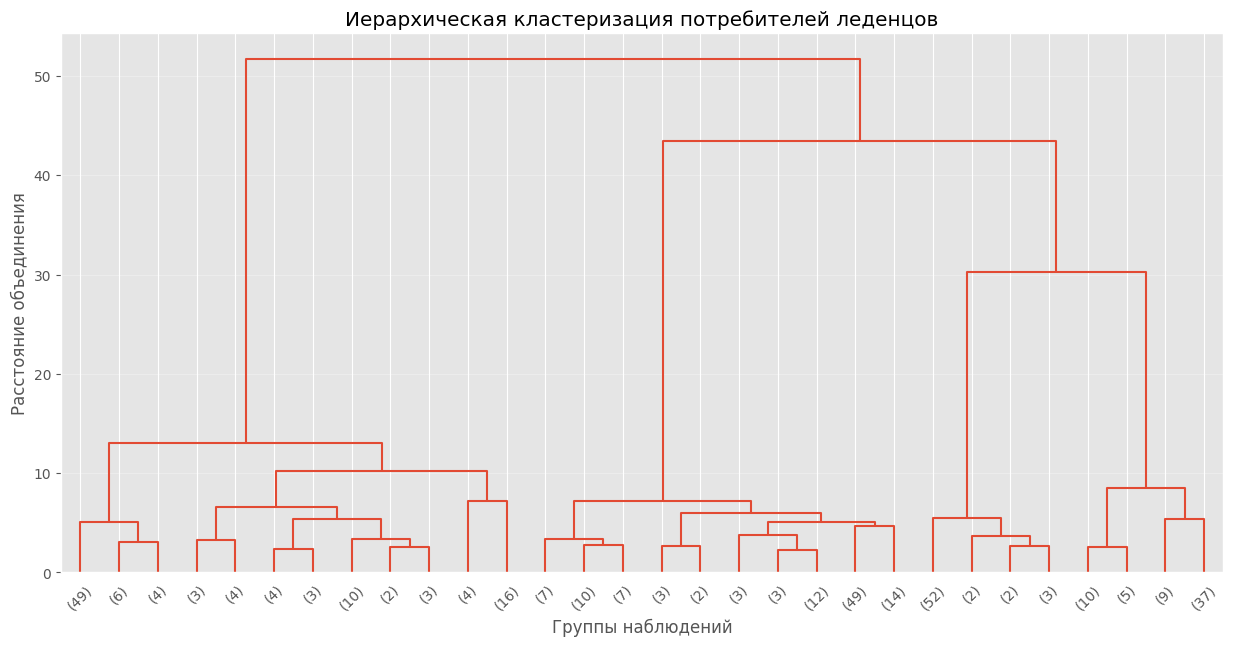

In [11]:

plt.figure(figsize=(15, 7))

dendrogram(
    link,
    # рассмотрим последние 30 групп для читаемости
    # дендрограммы
    truncate_mode='lastp',
    p=30,
    show_leaf_counts=True,
    color_threshold=0
)

plt.title('Иерархическая кластеризация потребителей леденцов')
plt.xlabel('Группы наблюдений')
plt.ylabel('Расстояние объединения')
plt.grid(axis='y', alpha=0.3)

plt.show()


Убираем цветовую гамму у дендрограммы и наблюдаем значительные расстояния между последовательными объединениями кластеров. Особенно заметен промежуток между уровнями приблизительно 13 и 30.

При проведении горизонтальной линии на уровне расстояния 25 выделяются четыре самостоятельные группы наблюдений. Это позволяет предварительно предположить наличие четырёх кластеров в исследуемых данных.

Для подтверждения выбранного числа кластеров необходимо дополнительно проанализировать расстояния между объединениями и содержательные характеристики полученных групп.

Проверяем это предположение, рассмотрев график локтя

Последние расстояния объединений:
[ 5.98  6.55  7.18  7.19  8.49 10.22 13.03 30.22 43.44 51.71]


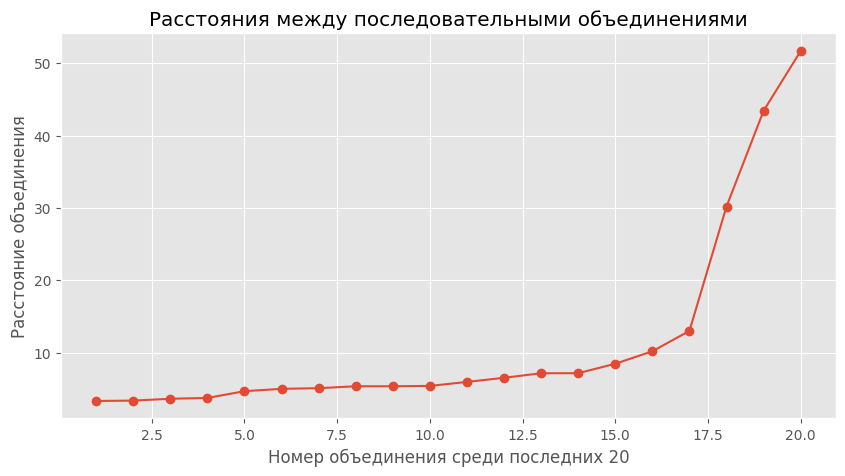

In [12]:
# Последние 10 расстояний объединения кластеров
distances = link[:, 2]

print("Последние расстояния объединений:")
print(np.round(distances[-10:], 2))

# График последних 20 объединений
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, 21),
    distances[-20:],
    marker='o'
)

plt.title('Расстояния между последовательными объединениями')
plt.xlabel('Номер объединения среди последних 20')
plt.ylabel('Расстояние объединения')
plt.grid(True)

plt.show()

На нём можно увидеть, что, начиная примерно с 17 (от 13.03 до 30.22 -> 30.22 - 13.03 = 17.19), алгоритм начинает объединять группы, существенно отличающиеся друг от друга. Из этого следует, что при проведении горизонтальной линии на расстоянии 17, мы получим, предположительно, оптимальное число кластеров, равное 4

In [13]:
# Выделение кластеров при пороге расстояния 17
clusters = fcluster(link, t=17, criterion='distance')

# Количество полученных кластеров
print("Количество кластеров:", len(np.unique(clusters)))

# Численность каждого кластера
print("\nРазмеры кластеров:")
print(pd.Series(clusters).value_counts().sort_index())

Количество кластеров: 4

Размеры кластеров:
1    108
2    110
3     59
4     61
Name: count, dtype: int64


При таком разделении кластеров, мы можем увидеть, что кластеры 1 и 2 являются наибольшими по объёму. Возможно сделать предположение, что порядка 60% респондентов  находится в первых двух кластерах.
Для дальнейшего определения различий признаков - рассчитаем средние значения признаков по кластерам.

In [14]:
# Создаём копию исходных данных
df_clusters = df.copy()

# Добавляем номера кластеров
df_clusters['Cluster'] = clusters

# Рассчитываем средние значения признаков по кластерам
cluster_means = df_clusters.groupby('Cluster').mean()

# Выводим таблицу
display(cluster_means.round(2))

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
Cluster,,,,,,,,,,,
1,2.82,2.83,2.77,2.62,2.61,2.58,2.75,2.92,4.95,4.81,4.86
2,4.85,4.80,4.84,4.68,3.04,3.04,3.00,2.99,3.07,3.05,3.05
3,3.00,2.97,2.97,2.92,2.92,2.95,4.92,4.92,3.00,3.00,3.00
4,3.00,3.00,3.00,3.00,4.85,4.85,3.00,2.92,2.75,2.75,2.75


Рассмотрим подробнее данные значение.
Для первого кластера наиболее выделяются признаки V9 - V11, это может говорить о том, что в рамках данного кластера располагаются респонденты, для которых важно принимать лединцы во время болезни, так как они значительно облегчают самочувствие.
Для второго кластера видим высокие показатели средних для признаков V1 - V4, что может говорить о том, что для респондентов важно свежее дыхание, устранение неприятного вкуса во рту и, как следствие, придаёт уверенности в себе.
Для третьего кластера характерны высокие показатели для признаков V7 и V8 - в данном случае респонденты связывают употребление леденцов с возможностью сосредоточиться, ненадолго отвлечься и подумать.
Последний кластер - любители сладкого, о чём говорят повышенные значения для признаков V5 и V6.

Следовательно, предположительная характеристика групп, описанная выше, хорошо соответствует полученным данным.

Для вызуализации различий между полученными группами воспользуемся тепловой картой

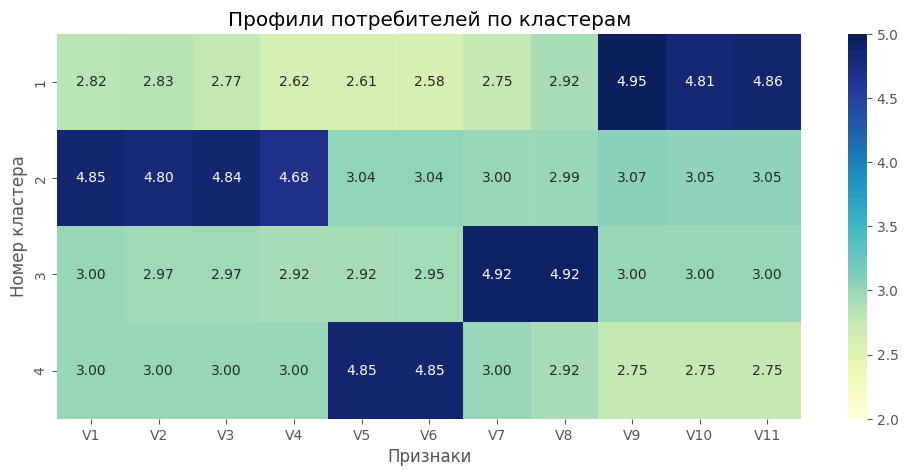

In [15]:
plt.figure(figsize=(12, 5))

sns.heatmap(
    cluster_means,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu',
    vmin=2,
    vmax=5
)

plt.title('Профили потребителей по кластерам')
plt.xlabel('Признаки')
plt.ylabel('Номер кластера')

plt.show()


**Вывод:**
## Вывод

В ходе лабораторной работы был проведён иерархический кластерный анализ потребителей леденцов на основе данных опроса 338 респондентов по 11 признакам, характеризующим основные мотивы потребления продукции.

На этапе предварительной обработки были изучены структура данных и описательная статистика. Установлено, что пропущенные значения отсутствуют, а признаки имеют сопоставимые масштабы измерения, поэтому кластеризация проводилась без дополнительной стандартизации.

Для выполнения кластерного анализа был выбран метод Варда с использованием евклидовой метрики расстояния. На основании построенной дендрограммы и анализа расстояний между последовательными объединениями было обосновано выделение **четырёх кластеров**. Наибольший скачок расстояния наблюдался между значениями 13,03 и 30,22, что позволило выбрать пороговое расстояние 17.

В результате анализа были выделены четыре группы потребителей:

1. **Оздоровительные потребители (108 человек, 31,95%)**
2. **Потребители, ориентированные на свежесть (110 человек, 32,54%)**
3. **Потребители, ориентированные на концентрацию и отдых (59 человек, 17,46%)**
4. **Любители сладкого (61 человек, 18,05%)**

Содержательная интерпретация кластеров была выполнена на основании средних значений признаков внутри каждой группы. Построенная тепловая карта наглядно продемонстрировала различия в потребностях выделенных сегментов.

Дополнительно было проведено сравнение трёх методов иерархической кластеризации: Уорда (Ward), полной связи (Complete) и средней связи (Average). Все методы показали одинаковое значение коэффициента силуэта — **0,727**, что свидетельствует о хорошем качестве разделения наблюдений. В качестве основного был сохранён метод Уорда, поскольку он позволил получить чётко интерпретируемые группы потребителей.
